In [1]:
import pandas as pd 
import numpy as np 
from sklearn.cluster import KMeans 
from sklearn.preprocessing import StandardScaler 
import matplotlib.pyplot as plt 
import seaborn as sns

In [6]:
# We will load the cleaned dataset from Section 1
df = pd.read_csv("../data/processed/cleaned_retail.csv")

In [8]:
# We used for recency calculation
snapshot_date=pd.to_datetime(df['InvoiceDate']).max() + pd.Timedelta(days=1)

In [13]:
# Snapshot date for recency calculation
snapshot_date = pd.to_datetime(df['InvoiceDate']).max() + pd.Timedelta(days=1)

# RFM calculation using correct column name
rfm = df.groupby('Customer ID').agg({
    'InvoiceDate': lambda x: (snapshot_date - pd.to_datetime(x).max()).days,
    'Invoice': 'count',
    'TotalPrice': 'sum'
}).rename(columns={'InvoiceDate':'Recency','Invoice':'Frequency','TotalPrice':'Monetary'})

print(rfm.head())


             Recency  Frequency  Monetary
Customer ID                              
12346.0          326         47    -51.74
12347.0            2        222   4921.53
12348.0           75         51   2019.40
12349.0           19        180   4404.54
12350.0          310         17    334.40


In [14]:
print("RFM head:\n",rfm.head())

RFM head:
              Recency  Frequency  Monetary
Customer ID                              
12346.0          326         47    -51.74
12347.0            2        222   4921.53
12348.0           75         51   2019.40
12349.0           19        180   4404.54
12350.0          310         17    334.40


In [11]:
print(df.columns)

Index(['Invoice', 'StockCode', 'Description', 'Quantity', 'InvoiceDate',
       'Price', 'Customer ID', 'Country', 'TotalPrice'],
      dtype='object')


In [16]:
# Now we will scale values 
scaler=StandardScaler()
rfm_scaled=scaler.fit_transform(rfm)

In [25]:
# K-Means Clustering 
kmeans=KMeans(n_clusters=6,random_state=42,n_init=10)
rfm['Cluster']=kmeans.fit_predict(rfm_scaled)

In [26]:
cluster_summary=rfm.groupby('Cluster').mean()
print("Cluster Summary:\n",cluster_summary)

Cluster Summary:
             Recency    Frequency       Monetary  cluster
Cluster                                                 
0        475.329913    40.834787     599.600561      0.0
1         74.182141   109.962589    1998.034023      1.0
2          1.800000  8474.400000   93239.322000      2.0
3          1.500000  2470.000000  546861.340000      3.0
4          6.400000  2167.600000  160782.188000      4.0
5         23.993631   785.436306   14766.968261      5.0


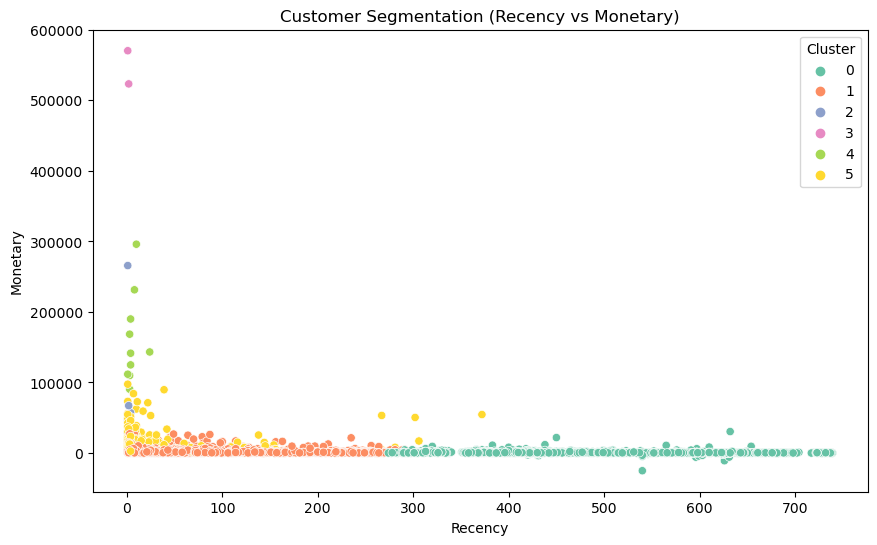

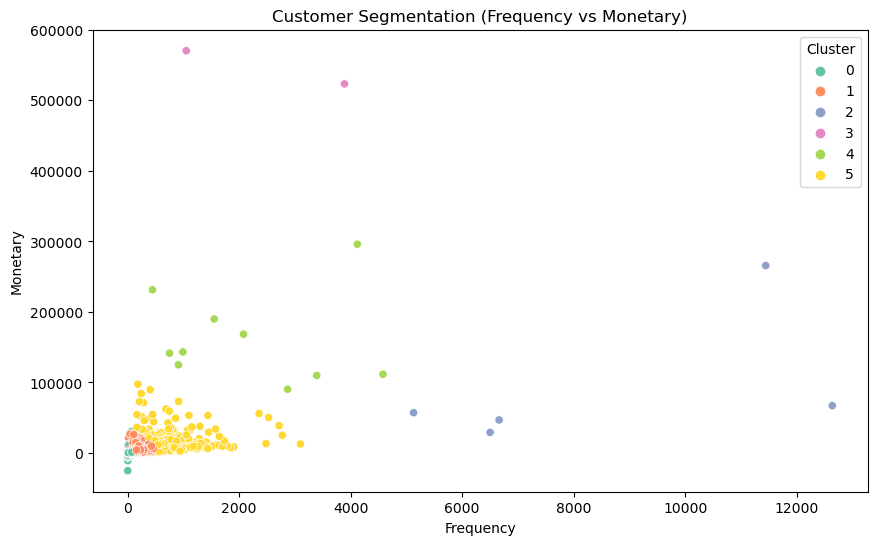

In [27]:
plt.figure(figsize=(10,6))
sns.scatterplot(x=rfm['Recency'], y=rfm['Monetary'], hue=rfm['Cluster'], palette="Set2")
plt.title("Customer Segmentation (Recency vs Monetary)")
plt.show()

plt.figure(figsize=(10,6))
sns.scatterplot(x=rfm['Frequency'], y=rfm['Monetary'], hue=rfm['Cluster'], palette="Set2")
plt.title("Customer Segmentation (Frequency vs Monetary)")
plt.show()

In [20]:
rfm.to_csv("../data/processed/customer_segments.csv",index=True)